# Fraud Detection

### Project Objective
Build a supervised machine learning model that detect probablity of fraud from Transaction Information.

#### Problem Type
Supervised Learning → Classification

#### Class Imbalance
We might have class imbalance, where legitimate transactions significantly outnumber fraudulent transactions. This is common in fraud detection because fraudulent transactions are relatively rare compared with legitimate transactions.

#### Target
 Class

### Table of Contents

1. Data Inspection

2. Data Cleaning

3. Exploratory Data Analysis and Visualization

4. Separate Features x and Target y

5. Split Train and Test Data

6. Preprocessing and Scaling

7. Model Training, Prediction and Evaluation

8. Model Comparison, Class Imbalance and Improvement

9. Final Model and New Predictions

10. Deployment

In [243]:
import pandas as pd
import numpy as np

## Data Inspection

In [244]:
# the data we are going to use to train, from this data, we will get our target y and feature x
df = pd.read_csv("creditcard.csv")

In [245]:
# what the first 30 row of the dataset looks like
df.head(30)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [246]:
# the train dataset contains 284,807, row and 81 columns
df.shape

(284807, 31)

In [247]:
#list of all the available column names
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [248]:
# list of all available columns,value row count, nan, and data types in the train dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [249]:
# the basic statistics of the whole dataset 
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [250]:
# showing the count of our Target "Class"
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [252]:
# Show how any total duplicate we have in the df
df.duplicated().sum()

np.int64(1081)

In [253]:
# Now let's inspect how those duplicates are distributed across the target "class".
df[df.duplicated(keep=False)]['Class'].value_counts()

Class
0    1822
1      32
Name: count, dtype: int64

In [254]:
# after counting, show all the values that are unique
df.nunique().sort_values()

Class          2
Amount     32767
Time      124592
V3        275663
V28       275663
V27       275663
V26       275663
V25       275663
V24       275663
V23       275663
V22       275663
V21       275663
V20       275663
V19       275663
V18       275663
V17       275663
V16       275663
V1        275663
V14       275663
V13       275663
V12       275663
V11       275663
V10       275663
V9        275663
V8        275663
V7        275663
V6        275663
V5        275663
V4        275663
V2        275663
V15       275663
dtype: int64

## Data Cleaning

In [255]:
# drop all the duplicates in the datasert and stored the rest back in a variable called df
df = df.drop_duplicates()

In [256]:
# After, the duplicate drop, we now have 283726 row and 31 column
df.shape

(283726, 31)

In [257]:
# show out the total sum of missing values or nan in each of the column (we have 0)
df.isnull().sum().sum()

np.int64(0)

In [258]:
# checking the data types if it needs any cleaning, (all are floats and ints)
df.dtypes.value_counts()

float64    30
int64       1
Name: count, dtype: int64

## Exploratory Data Analysis EDA and Visualization

In [259]:
import matplotlib.pyplot as plt
import seaborn as sns

In [260]:
# checking the distribution of our target, how many counts for class = 1 & 0
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [261]:
# Whats the percentage of "Class"
df['Class'].value_counts(normalize=True) * 100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

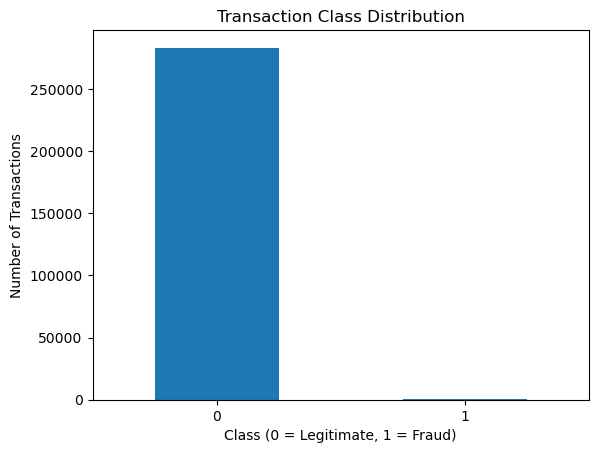

In [262]:
# Visualize the Imbalance

df['Class'].value_counts().plot(kind='bar')

# Styling and Cleaning
plt.title('Transaction Class Distribution')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

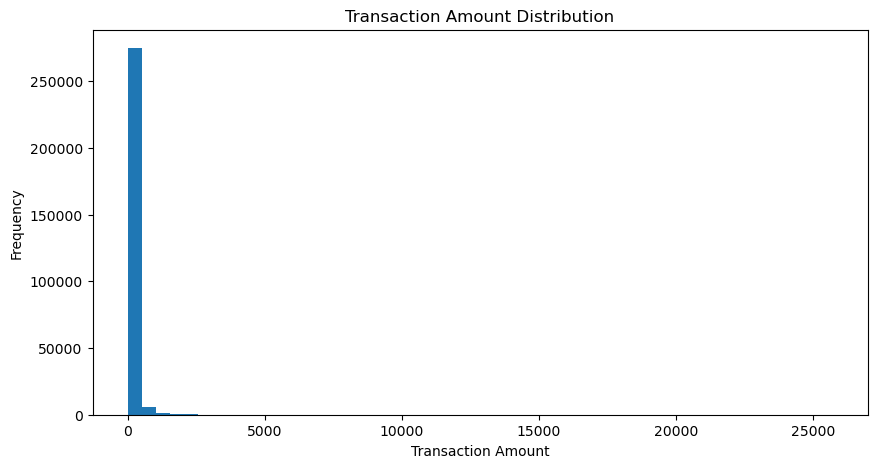

In [263]:
# Transaction Amount Distribution
# Show the distributions using Histogram, bins =50, grouped into 50 interval to see distribution, figsize of 10 width inches and 5 height tall inches

plt.figure(figsize=(10, 5))
plt.hist(df['Amount'], bins=50)
plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

<Figure size 800x500 with 0 Axes>

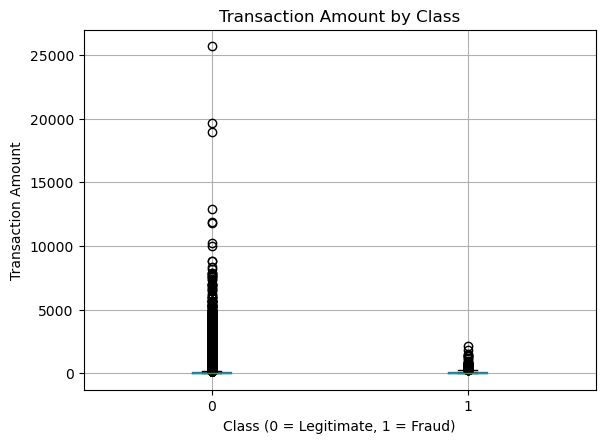

In [264]:
#Compare transaction amounts by class
#using seaborn box plot , figsize of 8 width inches and 5 height tall inches

plt.figure(figsize=(8, 5))

df.boxplot(column='Amount', by='Class')

plt.title('Transaction Amount by Class')
plt.suptitle('')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transaction Amount')
plt.show()

In [265]:
# Lets Compare the average amount by class
# group by class with their amount, showing aggregate of mean, median and max value in table
df.groupby('Class')['Amount'].agg(['mean', 'median', 'max'])

,mean,median,max
Class,,,
0,88.413575,22.00,25691.16
1,123.871860,9.82,2125.87


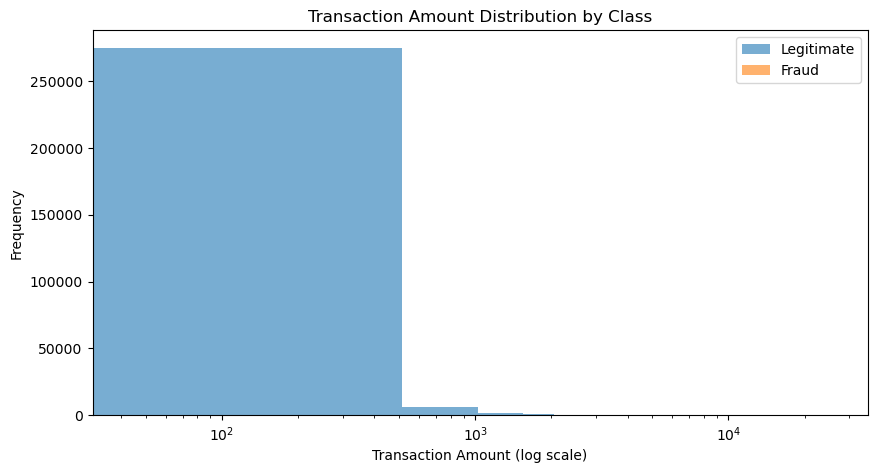

In [266]:
#Fraud vs legitimate transaction amounts
#Let's visualize the distributions more clearly using a logarithmic x-axis. This is useful because Amount is highly skewed.

plt.figure(figsize=(10, 5))
plt.hist(df[df['Class'] == 0]['Amount'], bins=50, alpha=0.6, label='Legitimate')
plt.hist(df[df['Class'] == 1]['Amount'], bins=50, alpha=0.6, label='Fraud')
plt.xscale('log')
plt.title('Transaction Amount Distribution by Class')
plt.xlabel('Transaction Amount (log scale)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

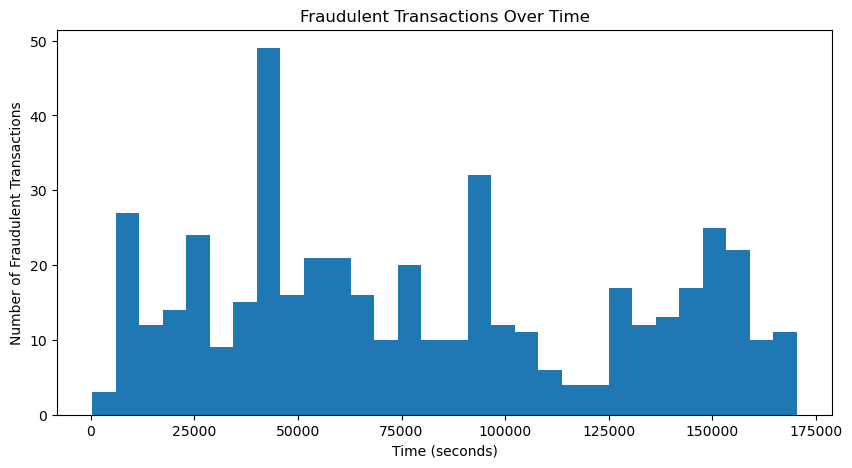

In [267]:
#We want to see whether fraud occurs differently across the transaction timeline. 
plt.figure(figsize=(10, 5))

plt.hist(df[df['Class'] == 1]['Time'], bins=30)

plt.title('Fraudulent Transactions Over Time')
plt.xlabel('Time (seconds)')
plt.ylabel('Number of Fraudulent Transactions')

plt.show()

## Separate Features X and Target y

In [268]:
# Before sepration, the original dataset contains 284,807, row and 31 columns
df.shape

(283726, 31)

In [269]:
#Here we seprate our x and y by removing ["Class"} from the dataframe and give it a variable of x
X = df.drop('Class', axis=1)

#confirm the shape, now our x only contain 283,726 row and 30 column
X.shape

(283726, 30)

In [270]:
# then assigned the target "Class" back to a variable of y 
y = df['Class']

# confirm the shape, now our y only contain the single column ["Class"} with 283,726 row 
y.shape

(283726,)

## Split Train and Test Data

In [272]:
# we import our ML library SkLearn, and select train test split from it ,it would allow us to test split our x,y into train\test set

from sklearn.model_selection import train_test_split

In [273]:
#here we splits our x, y into 80% : 20% ratio, 80% training data for learning and 20% testing data for evaluating the model,
#text_size = 0.2 means keep the test size 20% on each x,y
#random_state=42 makes sure we get the same split every time we run the code.
#stratify=When you divide the data, preserve the Class 0 and Class 1 proportions in both the training and test sets, no miss-approprate (because of imbalance) 

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

# showing all the shape 
print("X_train:", X_train.shape) # showing the shape of x_train 80%
print("X_test:", X_test.shape) # showing the shape of x_test 20%
print("y_train:", y_train.shape) # showing the shape of y_train 80%
print("y_test:", y_test.shape) # showing the shape of y_test 20%

X_train: (226980, 30)
X_test: (56746, 30)
y_train: (226980,)
y_test: (56746,)


## Preprocessing and Scaling

In [275]:
# This import library is used to scale numerical features : Scaling puts features on a comparable range for models such as Logistic Regression
from sklearn.preprocessing import StandardScaler

In [276]:
# We're creating a scaler object, Think of it as a tool that will standardize the numerical features.
scaler = StandardScaler()

In [277]:
# here we created a variable (X_train_scaled) to wrap up or apply our preprocessing using scaler
X_train_scaled = scaler.fit_transform(X_train)

#confirming the x_train_scaled after prepocssing (the shape remain the same)
X_train_scaled.shape

(226980, 30)

In [278]:
# here we created a variable (X_test_scaled) to wrap up or apply our preprocessing using scaler
X_test_scaled = scaler.transform(X_test)

#confirming the x_test_scaled after prepocssing (the shape remain the same)
X_test_scaled.shape

(56746, 30)

## Model Training, Prediction and Evaluation

### Logistic Regression Model

We will start with Logistic Regression as our baseline model. It uses the training data to learn the relationship between the transaction features and the probability of fraud. Logistic Regression predicts a class (fraud or legitimate) using probabilities, making it a good starting point for binary classification.

In [279]:
# importing the LogisticsRegression algorithm model
from sklearn.linear_model import LogisticRegression

In [280]:
# Created a variable called log_reg for the Logistic Regression algorithm model
logreg_model = LogisticRegression()

In [281]:
# This will makes the model variable learn the relationship between the house features (x_train_scaled) and Class(y_train).
# Train the Logistic Regression model using the training data

logreg_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [282]:
# using our reserved 20% feature df to test the model and predict using (logreg_model.predict) then answer to be store into logreg_pred variable
# Make predictions on the test data
logreg_pred = logreg_model.predict(X_test_scaled)

In [283]:
# our prediction , we have about 56,746 predictions here, (The 0,0,0, means the model predicted legitimate transactions.1 would mean fraud.) 
logreg_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### Confusion Matrix metrics 1 

In [ ]:
#importing confusion Matrix library for metric 1 evaluation
from sklearn.metrics import confusion_matrix

In [ ]:
#Shows the number of correct and incorrect predictions (y_test = the truth, logreg_pred = what the model said  and confusion_matrix() = compares the two.)
confusion_matrix(y_test, logreg_pred)

##### Classification Report metrics 2

In [284]:
# importing classification report library for metric 2 evaluation
from sklearn.metrics import classification_report

In [286]:
# Generate the classification report and show the result using the data we used to test it and the predictions
print(classification_report(y_test, logreg_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



##### ROC and AUC metrics 3

In [287]:
#importing ROC and AUC library for metric 3 evaluation
from sklearn.metrics import roc_auc_score

In [288]:
# Get the probability of each transaction being fraud in our "logreg_model" using "x_test_scaled" 20% dataset for testing target
# [:, 1] The 1 means take the second column, which is the probability of Class 1 (fraud) since we are looking for the proba of fraud
# then store it in a variable called logreg_proba

logreg_proba = logreg_model.predict_proba(X_test_scaled)[:, 1]

# show the result of first 5
logreg_proba[:5]

array([2.49737759e-04, 2.04864321e-04, 9.41796667e-05, 1.44483188e-04,
       1.15793577e-03])

In [338]:
# Calculate the ROC-AUC score using the 20% dataset of target "y_test" and fraud probabilities "logreg_proba", then store it in a variable called roc_auc
logreg_rocauc = roc_auc_score(y_test, logreg_proba)

# show the result
print("ROC-AUC:", logreg_rocauc)

ROC-AUC: 0.9560466717268892


reading it this way:

ROC-AUC: 0.9560466717268892

This is approximately 95.6%.

It means:
The Logistic Regression model has a strong ability to distinguish fraudulent transactions from legitimate transactions across different probability thresholds.

## XGBoost Model

XGBoost is a tree-based classification algorithm that builds multiple decision trees sequentially to improve prediction accuracy. It can capture complex relationships between features and the target.

In [290]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [302]:
# Import the XGBoost classification algorithm model
from xgboost import XGBClassifier

In [301]:
# Create a variable called xgb_model for the XGBoost classification model
xgb_model = XGBClassifier()

In [304]:
# Train the XGBoost model using the training data
## This will makes the model variable learn the relationship between 80% features (x_train_scaled) and 80% target(y_train).
xgb_model.fit(X_train_scaled, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [305]:
# Use the trained model to test features (X_test_scaled) and predict the target, then store those predictions in a variable of xgb_pred.
# using our reserved 20% feature df to test the model and predict using (xgb_model.predict) then answer to be store into xgb_pred variable
xgb_pred = xgb_model.predict(X_test_scaled)

In [ ]:
# our prediction for xgb model
xgb_pred

##### Confusion Matrix metrics 1 

In [306]:
#importing confusion Matrix library for metric 1 evaluation
from sklearn.metrics import confusion_matrix

In [296]:
# Shows the number of correct and incorrect predictions (y_test = the truth, xgb_pred = what the model said  and confusion_matrix() = compares the two.)
confusion_matrix(y_test, xgb_pred)

array([[56629,    22],
       [   29,    66]])

##### Classification Report metrics 2

In [307]:
# importing classification report library for metric 2 evaluation
from sklearn.metrics import classification_report

In [308]:
# Generate the classification report and show the result using the data we used to test it and the predictions
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.75      0.69      0.72        95

    accuracy                           1.00     56746
   macro avg       0.87      0.85      0.86     56746
weighted avg       1.00      1.00      1.00     56746



##### ROC and AUC metrics 3

In [309]:
#importing ROC and AUC library for metric 3 evaluation
from sklearn.metrics import roc_auc_score

In [310]:
# Get the probability of each transaction being fraud in our "xgb_model" using "x_test_scaled" 20% dataset for testing target
# [:, 1] The 1 means take the second column, which is the probability of Class 1 (fraud) since we are looking for the proba of fraud
# then store it in a variable called xgb_proba

xgb_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

# show the result of first 5
xgb_proba[:5]

array([2.5592826e-06, 1.8683739e-05, 9.5828727e-04, 1.8020352e-06,
       8.0415462e-05], dtype=float32)

In [335]:
# Calculate the ROC-AUC score using the 20% dataset of target "y_test" and fraud probabilities "logreg_proba", then store it in a variable called roc_auc
xgb_rocauc = roc_auc_score(y_test, xgb_proba)

# show the result
print("ROC-AUC:", xgb_rocauc)

ROC-AUC: 0.8574630075745399


### LightGBM Model

LightGBM is a tree-based classification algorithm that uses gradient boosting to build models efficiently. It can handle large datasets and capture complex relationships between features and the target.

In [312]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [314]:
# Import the LightGBM classification algorithm model
from lightgbm import LGBMClassifier

In [316]:
# Create a variable called xgb_model for the LightGBM classification model
lgbm_model = LGBMClassifier()

In [317]:
# Train the LightGBM model using the training data
## This will makes the model variable learn the relationship between 80% features (x_train_scaled) and 80% target(y_train).
lgbm_model.fit(X_train_scaled, y_train)

[LightGBM] [Info] Number of positive: 378, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.091709 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 226980, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001665 -> initscore=-6.396056
[LightGBM] [Info] Start training from score -6.396056


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [319]:
# Use the trained model to test features (X_test_scaled) and predict the target, then store those predictions in a variable of lgbm_pred.
# using our reserved 20% feature df to test the model and predict using (xgb_model.predict) then answer to be store into lgbm_pred variable
lgbm_pred = lgbm_model.predict(X_test_scaled)

In [320]:
# our prediction for xgb model
lgbm_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### Confusion Matrix metrics 1 

In [321]:
#importing confusion Matrix library for metric 1 evaluation
from sklearn.metrics import confusion_matrix

In [322]:
# Shows the number of correct and incorrect predictions (y_test = the truth, lgbm_pred = what the model said  and confusion_matrix() = compares the two.)
confusion_matrix(y_test, lgbm_pred)

array([[56478,   173],
       [   41,    54]])

##### Classification Report metrics 2

In [325]:
# importing classification report library for metric 2 evaluation
from sklearn.metrics import classification_report

In [324]:
# Generate the classification report and show the result using the data we used to test it and the predictions
print(classification_report(y_test, lgbm_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.24      0.57      0.34        95

    accuracy                           1.00     56746
   macro avg       0.62      0.78      0.67     56746
weighted avg       1.00      1.00      1.00     56746



##### ROC and AUC metrics 3

In [327]:
#importing ROC and AUC library for metric 3 evaluation
from sklearn.metrics import roc_auc_score

In [329]:
# Get the probability of each transaction being fraud in our "lgbm_model" using "x_test_scaled" 20% dataset of features, for testing target
# [:, 1] The 1 means take the second column, which is the probability of Class 1 (fraud) since we are looking for the proba of fraud
# then store it in a variable called xgb_proba

lgbm_proba = lgbm_model.predict_proba(X_test_scaled)[:, 1]

# show the result of first 5
lgbm_proba[:5]

array([0.00000000e+00, 1.99207383e-09, 3.49174637e-08, 3.02688649e-08,
       1.00529739e-07])

In [336]:
# Calculate the ROC-AUC score using the 20% dataset of target "y_test" and fraud probabilities "lgbm_proba", then store it in a variable called roc_auc
lgbm_rocauc = roc_auc_score(y_test, lgbm_proba)

# show the result
print("ROC-AUC:", lgbm_rocauc)

ROC-AUC: 0.7688490657014462


## Model Comparison, Class Imbalance and Improvement

In [341]:
# here we created our table for comparison through pd.dataframe, output will be stack all the model name and metrics in column while row contain metrics value
# It is noted that metrics 2 (Precison, Recall, F1) and metrics 3 (Roc-Auc) result are what we are using for comparison

model_comparison = pd.DataFrame({
    
    "Model": ["Logistic Regression", "XGBoost", "LightGBM"],
 
    "Precision": [ precision_score(y_test, logreg_pred), precision_score(y_test, xgb_pred), precision_score(y_test, lgbm_pred) ],
    
    "Recall": [ recall_score(y_test, logreg_pred), recall_score(y_test, xgb_pred),recall_score(y_test, lgbm_pred)],
    
    "F1": [ f1_score(y_test, logreg_pred),   f1_score(y_test, xgb_pred),   f1_score(y_test, lgbm_pred)  ],
   
    "ROC-AUC": [ logreg_rocauc,   xgb_rocauc, lgbm_rocauc ]
})


#display the table
model_comparison

,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.846154,0.578947,0.687500,0.956047
1,XGBoost,0.750000,0.694737,0.721311,0.857463
2,LightGBM,0.237885,0.568421,0.335404,0.768849


### Class Imbalance (Improvement | Tunning)

The dataset is highly imbalanced, with fraud transactions representing only a small fraction of all transactions.
Instead of resampling the data immediately, we will first use class weighting. This gives more importance to the minority class during model training.

#### Balanced Logistics Regression 

In [353]:
# Create a Logistic Regression model with balanced class weights here 
balanced_logreg = LogisticRegression(class_weight='balanced')

In [355]:
# now that the hyperparameter class_weight hs been embeded, lets Train a new model with it, balanced Logistic Regression model
balanced_logreg.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [357]:
# Make predictions using the balanced Logistic Regression model
balanced_logreg_pred = balanced_logreg.predict(X_test_scaled)

In [358]:
#our prediction
balanced_logreg_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### Confusion Matrix, Classification Report and Roc-Auc Metrics 

In [359]:
# Evaluate the balanced Logistic Regression model using all 3 metrics together
# using all the 3 metrics here all together , to avoid clutter, metrics 2 & 3

# Confusion Matrix Metrics 1 
print("Confusion Matrix:")
print(confusion_matrix(y_test, balanced_logreg_pred))

# Classification Report Metrics 2
print("\nClassification Report:") #\n means new line
print(classification_report(y_test, balanced_logreg_pred))

# Roc-Auc Metrics 3 
balanced_logreg_prob = log_reg_balanced.predict_proba(X_test_scaled)[:, 1] #fraud probablity slashing before roc_auc
balanced_logreg_rocauc = roc_auc_score(y_test, balanced_logreg_prob)
print("ROC-AUC:",  balanced_logreg_rocauc)

Confusion Matrix:
[[55262  1389]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

ROC-AUC: 0.9656548079701293


#### Balanced XGBoost

In [ ]:
we find our scale_pos_weight first 

In [364]:
# count each total value from our y_train (80% target df) on each class, (0 "legitimate' and 1 "Fraud"), divide it 
# the ratio will be 226602 / 378 = 599.476 and then store it in a variable called Xgb_scaleposweight
Xgb_scaleposweight = y_train.value_counts()[0] / y_train.value_counts()[1]

#show the result 
Xgb_scaleposweight

np.float64(599.4761904761905)

In [372]:
# we assigned the above result here (scale_pos_weight = 599.48)
balanced_xgb = XGBClassifier(scale_pos_weight=599.48)

In [373]:
# Our Training happen here Train the balanced XGBoost model
balanced_xgb.fit(X_train_scaled, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [376]:
#make the predciton for balanced xgb pred
balanced_xgb_pred = balanced_xgb.predict(X_test_scaled)

#our prediction
balanced_xgb_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### Confusion Matrix, Classification Report and Roc-Auc Metrics 

In [377]:
# Evaluate the balanced Logistic Regression model using all 3 metrics together
# using all the 3 metrics here all together , to avoid clutter, metrics 2 & 3 

# Confusion Matrix Metrics 1 
print("Confusion Matrix:")
print(confusion_matrix(y_test, balanced_xgb_pred))

# Classification Report Metrics 2
print("\nClassification Report:") #\n means new line
print(classification_report(y_test, balanced_xgb_pred))

# Roc-Auc Metrics 3 
balanced_xgb_prob = balanced_xgb.predict_proba(X_test_scaled)[:, 1] #fraud probablity slashing before roc_auc
balanced_xgb_rocauc = roc_auc_score(y_test, balanced_xgb_prob)
print("ROC-AUC:",  balanced_xgb_rocauc)

Confusion Matrix:
[[56649     2]
 [   21    74]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.78      0.87        95

    accuracy                           1.00     56746
   macro avg       0.99      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9727701187975498


#### Balanced LightGBM

In [391]:
# Create a LightGB model with balanced class weights here 
balanced_lgbm = LGBMClassifier(class_weight='balanced')

In [392]:
# now that the hyperparameter class_weight hs been embeded, lets Train a new model with it, balanced LightGB model
balanced_lgbm.fit(X_train_scaled, y_train)

[LightGBM] [Info] Number of positive: 378, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.101686 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 226980, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [393]:
#make the predciton for balanced xgb pred
balanced_lgbm_pred = balanced_lgbm.predict(X_test_scaled)

#our prediction
balanced_lgbm_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### Confusion Matrix, Classification Report and Roc-Auc Metrics 

In [396]:
# Evaluate the balanced Logistic Regression model using all 3 metrics together
# using all the 3 metrics here all together , to avoid clutter, metrics 2 & 3 

# Confusion Matrix Metrics 1 
print("Confusion Matrix:")
print(confusion_matrix(y_test, balanced_lgbm_pred))

# Classification Report Metrics 2
print("\nClassification Report:") #\n means new line
print(classification_report(y_test, balanced_lgbm_pred))

# Roc-Auc Metrics 3 
balanced_lgbm_prob = balanced_lgb.predict_proba(X_test_scaled)[:, 1] #fraud probablity slashing before roc_auc
balanced_lgbm_rocauc = roc_auc_score(y_test, balanced_lgbm_prob)
print("ROC-AUC:",  balanced_lgbm_rocauc)

Confusion Matrix:
[[56637    14]
 [   22    73]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.84      0.77      0.80        95

    accuracy                           1.00     56746
   macro avg       0.92      0.88      0.90     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9643283112018276


## Final Model and New Predictions

In [398]:
# Create a final comparison table showing all 6 model results
## here we created our table for comparison through pd.dataframe, output will be stack all the model name and metrics in column while row contain metrics value
# It is noted that metrics 2 (Precison, Recall, F1) and metrics 3 (Roc-Auc) result are what we are using for comparison

final_comparison = pd.DataFrame({
    "Model": [ "Logistic Regression", "XGBoost", "LightGBM", "Balanced Logistic Regression",  "Balanced XGBoost",  "Balanced LightGBM" ],

    "Precision": [ precision_score(y_test, logreg_pred), precision_score(y_test, xgb_pred), precision_score(y_test, lgbm_pred), 
                   precision_score(y_test, balanced_logreg_pred), precision_score(y_test, balanced_xgb_pred), precision_score(y_test, balanced_lgbm_pred) ],
    
    "Recall": [ recall_score(y_test, logreg_pred), recall_score(y_test, xgb_pred), recall_score(y_test, lgbm_pred), recall_score(y_test, balanced_logreg_pred),
               recall_score(y_test, balanced_xgb_pred), recall_score(y_test, balanced_lgbm_pred) ],
    
    "F1": [ f1_score(y_test, logreg_pred), f1_score(y_test, xgb_pred),f1_score(y_test, lgbm_pred), f1_score(y_test, balanced_logreg_pred),
            f1_score(y_test, balanced_xgb_pred), f1_score(y_test, balanced_lgbm_pred) ],

    "ROC-AUC": [ logreg_rocauc, xgb_rocauc, lgbm_rocauc, balanced_logreg_rocauc, balanced_xgb_rocauc, balanced_lgbm_rocauc]
})

final_comparison





,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.846154,0.578947,0.687500,0.956047
1,XGBoost,0.750000,0.694737,0.721311,0.857463
2,LightGBM,0.237885,0.568421,0.335404,0.768849
3,Balanced Logistic Regression,0.056386,0.873684,0.105935,0.965655
4,Balanced XGBoost,0.973684,0.778947,0.865497,0.972770
5,Balanced LightGBM,0.839080,0.768421,0.802198,0.964328


 ##### Hyperparameter Tuning for XGBoost

In [404]:
# Create the tuned XGBoost model


# hyperparmeter tunning happen herr
bal_xgb_tuned = XGBClassifier(
    scale_pos_weight=Xgb_scaleposweight, # we brought our scale_pos_weight variable to handle the class imbalance again on the final model
    n_estimators=200, # How many trees? Use 200 decision trees
    max_depth=5, # How complex can each tree become? Maximum depth of 3 or Limit each tree to a maximum depth of 3
    learning_rate=0.05, # How strongly does each tree correct the model? Small steps of 0.05 or Controls how much each tree contributes to the model
    random_state=42 # Keep the random process consistent,same result each run
)


# Train the bal_xgb_tuned here 
bal_xgb_tuned.fit(X_train_scaled, y_train)


# Make predictions using the balanced tuned XGBoost model
bal_xgb_tuned_pred = bal_xgb_tuned.predict(X_test_scaled)


# prediction on the model
bal_xgb_tuned_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

##### The Metrics 1, 2, 3

In [409]:
# Evaluate the tuned XGBoost model using all 3 metrics

# Confusion Matrix,Metric 1
print("Confusion Matrix:")
print(confusion_matrix(y_test, bal_xgb_tuned_pred))

# Classification Report,Metric 2
print("\nClassification Report:")
print(classification_report(y_test, bal_xgb_tuned_pred))

# ROC-AUC,Metric 3
bal_xgb_tuned_prob = bal_xgb_tuned.predict_proba(X_test_scaled)[:, 1]

bal_xgb_tuned_rocauc = roc_auc_score(y_test, bal_xgb_tuned_prob)

print("ROC-AUC:", bal_xgb_tuned_rocauc)

Confusion Matrix:
[[56604    47]
 [   19    76]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.62      0.80      0.70        95

    accuracy                           1.00     56746
   macro avg       0.81      0.90      0.85     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.970551734581728


##### New Prediction

In [411]:
# we stored the selected final model "balanced_xgb" into a varibale called final_model
final_model = balanced_xgb

In [412]:
# Make predictions using the final model
final_pred = final_model.predict(X_test_scaled)

In [414]:
# Get the fraud probability for each transaction ([:, 1] “take the probability for class 1 (Fraud) only)
final_prob = final_model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
# Create a table showing the final predictions and fraud probabilities compare with  actual original datset (y_test, 20% df of target)
final_results = pd.DataFrame({ "Actual": y_test.values, "Prediction": final_pred,"Fraud_Probability": final_prob})

In [417]:
# show the first 20 result of the table
final_results.head(10)

,Actual,Prediction,Fraud_Probability
0,0,0,3.440420e-07
1,0,0,2.856801e-06
2,0,0,3.082438e-05
3,0,0,3.043637e-07
4,0,0,5.618333e-06
5,0,0,1.340877e-06
6,0,0,1.430789e-06
7,0,0,1.739989e-07
8,0,0,4.761864e-06
9,0,0,1.487954e-07


###### Final result output note:

The `Fraud_Probability` values are displayed in scientific notation because they are very small. For example, `3.44e-07` means approximately `0.000000344`.
These very low probabilities indicate that the model is highly confident that these transactions are **legitimate (Class 0)**.

In [418]:
# Display transactions predicted as fraud through filtering == 1 ( 1 fraud)
final_results[final_results["Prediction"] == 1].head(10)

,Actual,Prediction,Fraud_Probability
845,1,1,0.999372
1339,1,1,0.999995
2146,1,1,0.999989
4865,1,1,0.999994
5505,1,1,0.856197
5638,1,1,1.000000
5759,1,1,0.999982
6673,1,1,0.999990
7011,1,1,0.999994
8671,1,1,0.999954


###### Final result output note:
These transactions were all **correctly predicted as fraud (Class 1)**. The `Fraud_Probability` values are very high, showing that the model is highly confident that these transactions are fraudulent.
For example, `0.999995` means approximately **99.9995% fraud probability**, while `0.856197` means approximately **85.62% fraud probability**.

##### Prediction Export

In [425]:
# Create a table containing Transaction_index (from feature dataset testing), Actual(from target dataset testing) Predictions and Fraud_probability.

submission = pd.DataFrame({ "Transaction_Index": X_test.index, "Actual": y_test.values,"Prediction": final_pred,"Fraud_Probability": final_prob })

# show the first 5 head 
submission.head()

,Transaction_Index,Actual,Prediction,Fraud_Probability
0,86568,0,0,3.440420e-07
1,251557,0,0,2.856801e-06
2,20232,0,0,3.082438e-05
3,68952,0,0,3.043637e-07
4,191852,0,0,5.618333e-06


In [427]:
# Export the final predictions to a CSV file with No default indexing
submission.to_csv("fraud_predictions.csv", index=False)

## Deployment 

We will save the final model and preprocessing pipeline so they can be loaded later to make predictions on new Credit card transactions.

The model can now be loaded later to make predictions on new transactions without retraining. The scaler is also saved because new data must go through the same preprocessing used during training.

In [428]:
# Import joblib to save and load our trained model and preprocessor engine
import joblib

In [429]:
 # dump & save the final model into pkl file as fraud_detection_model.pkl (for backend or fastAPI purposes)
joblib.dump(final_model, "fraud_detection_model.pkl")

['fraud_detection_model.pkl']

In [430]:
# dump & save the scaler system engine we used to scaled the dataset,into pkl file as fraud_price_detection_scaler.pkl (for backend or fastAPI purposes)
joblib.dump(scaler, "fraud_detection_scaler.pkl")

['fraud_detection_scaler.pkl']

In [434]:
# Import OS to work with files and folders in the operating systemimport os

In [436]:
# List all files and folders in the current working directory
os.listdir()

['.ipynb_checkpoints',
 'creditcard.csv',
 'Fraud_Detection_ML.ipynb',
 'fraud_detection_model.pkl',
 'fraud_detection_scaler.pkl',
 'fraud_predictions.csv']

In [437]:
# we are now putting our model we loaded into a pkl file for a variable called loaded_model
loaded_model = joblib.load("fraud_detection_model.pkl")

# verifying it
type(loaded_model)

xgboost.sklearn.XGBClassifier

In [440]:
# For Preprocessor & scaler engine 
# we are now putting our scaler logics engine into a variable called loaded_model
loaded_scaler = joblib.load("fraud_detection_scaler.pkl")

# verifying
type(loaded_scaler)

sklearn.preprocessing._data.StandardScaler

##### Final Testing through .pkl files

In [441]:
# Transform the test data (x_test, original 20% feautres dataset) using the loaded scaler (.pkl) to do the transform
X_test_loaded = loaded_scaler.transform(X_test)

# Make predictions using the loaded model (.pkl) of course on x test too but already trasnformed(x_test_loaded)
loaded_pred = loaded_model.predict(X_test_loaded)

# Now Display the first 10 predictions
loaded_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [442]:
# Check whether the loaded model produces the same predictions, loaded pred ( .pkl predictions) vs fina_pred (from our final model var )
(loaded_pred == final_pred).all()

np.True_